# 01 – Exploratory data analysis

Analysis cohort: 1,737 four-year institutions (built by `python -m src.clean`). EDA uses the **training split only** so nothing about the test set informs modelling choices; the cohort-level counts are in `docs/cohort_review.md`.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import load_cohort

sns.set_theme(style='whitegrid', context='notebook')
df = load_cohort()
train = df[df.split == 'train'].copy()
train['control'] = train.CONTROL.map(C.CONTROL_LABELS)
train.shape

(1389, 35)

## Target: first-year retention (`RET_FT4`)

count    1389.000
mean        0.744
std         0.138
min         0.044
25%         0.673
50%         0.759
75%         0.838
max         0.993
Name: RET_FT4, dtype: float64

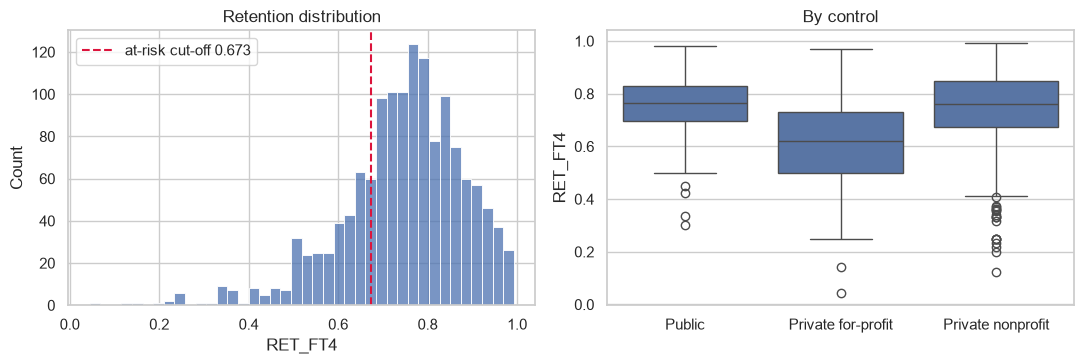

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(train[C.TARGET], bins=40, ax=ax[0])
cut = train.loc[train.at_risk == 1, C.TARGET].max()
ax[0].axvline(cut, color='crimson', ls='--', label=f'at-risk cut-off {cut:.3f}')
ax[0].legend(); ax[0].set_title('Retention distribution')
sns.boxplot(data=train, x='control', y=C.TARGET, ax=ax[1]); ax[1].set_title('By control'); ax[1].set_xlabel('')
plt.tight_layout()
plt.savefig('../results/figures/retention_distribution.png', dpi=150, bbox_inches='tight')
train[C.TARGET].describe().round(3)

## Missing values

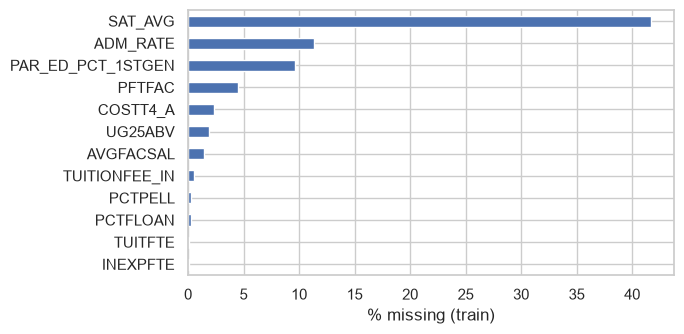

In [3]:
miss = train[C.FEATURES].isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
ax = (100 * miss).plot.barh(figsize=(7, 3.5)); ax.invert_yaxis(); ax.set_xlabel('% missing (train)')
plt.tight_layout()

In [4]:
# Is missingness informative? Retention when SAT / admission rate are missing vs present.
pd.DataFrame({c: train.groupby(train[c].isna())[C.TARGET].mean() for c in ['SAT_AVG', 'ADM_RATE', 'PAR_ED_PCT_1STGEN']}).rename(index={False: 'present', True: 'missing'}).round(3)

,SAT_AVG,ADM_RATE,PAR_ED_PCT_1STGEN
present,0.787,0.761,0.742
missing,0.685,0.609,0.762


## Correlation of each numeric feature with retention (Spearman)

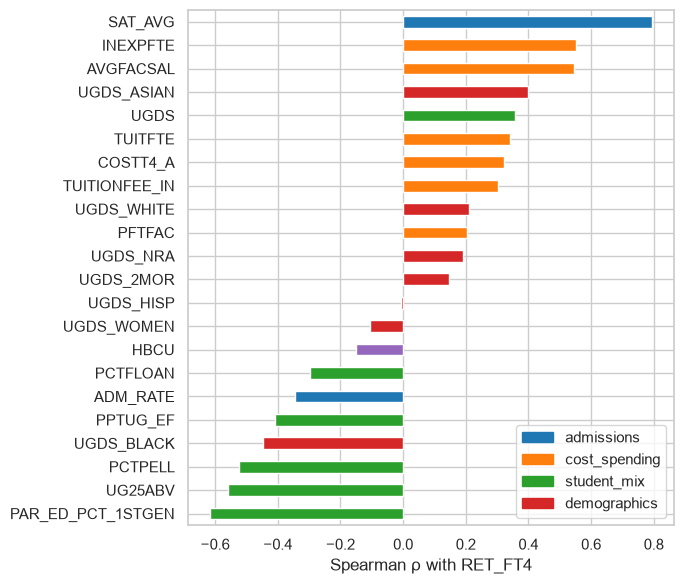

In [5]:
corr = train[C.NUMERIC + [C.TARGET]].corr(method='spearman')[C.TARGET].drop(C.TARGET).sort_values()
group_of = {c: g for g, cols in C.FEATURE_GROUPS.items() for c in cols}
colors = dict(zip(C.FEATURE_GROUPS, sns.color_palette('tab10')))
ax = corr.plot.barh(figsize=(7, 6), color=[colors[group_of[c]] for c in corr.index])
ax.set_xlabel('Spearman ρ with RET_FT4')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items() if k != 'institution_type'], loc='lower right')
plt.tight_layout()
plt.savefig('../results/figures/feature_correlations.png', dpi=150, bbox_inches='tight')

## Strongest relationships

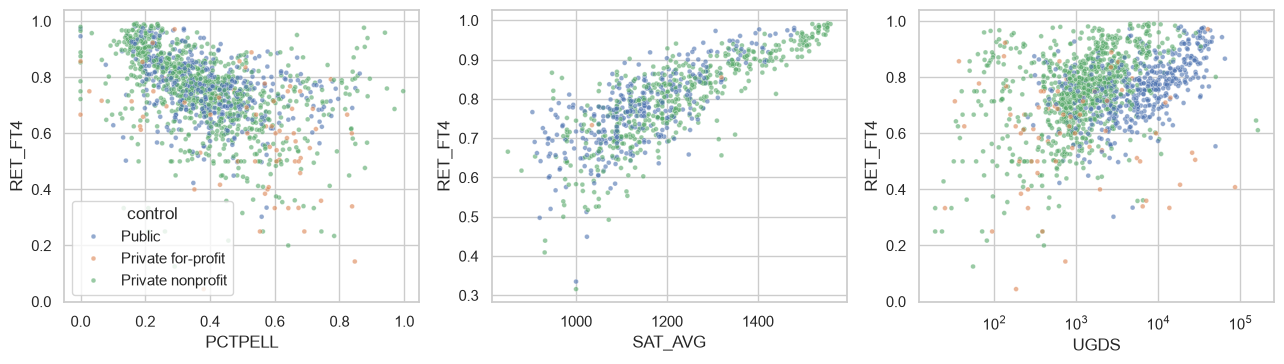

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ['PCTPELL', 'SAT_AVG', 'UGDS']):
    sns.scatterplot(data=train, x=col, y=C.TARGET, hue='control', s=12, alpha=.6, ax=ax, legend=ax is axes[0])
axes[2].set_xscale('log')
plt.tight_layout()
plt.savefig('../results/figures/key_relationships.png', dpi=150, bbox_inches='tight')

## Feature collinearity

Highly correlated pairs matter for interpreting linear coefficients (ridge/lasso) and permutation importance.

In [7]:
c = train[C.NUMERIC].corr(method='spearman')
pairs = c.where(np.triu(np.ones(c.shape, bool), 1)).stack()
pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_frame('ρ')

ρ
COSTT4_A      TUITIONFEE_IN      0.95
UG25ABV       PPTUG_EF           0.79
TUITIONFEE_IN TUITFTE            0.78
COSTT4_A      TUITFTE            0.76
UG25ABV       PAR_ED_PCT_1STGEN  0.70
SAT_AVG       PAR_ED_PCT_1STGEN -0.70
              PCTPELL           -0.67
AVGFACSAL     UGDS               0.66
SAT_AVG       INEXPFTE           0.65
AVGFACSAL     UGDS_ASIAN         0.64
PCTPELL       PAR_ED_PCT_1STGEN  0.62
SAT_AVG       UG25ABV           -0.61

## Small schools are noisy

In [8]:
train['size_band'] = pd.cut(train.UGDS, [0, 500, 1000, 5000, np.inf], labels=['≤500', '501–1k', '1k–5k', '>5k'])
train.groupby('size_band', observed=True)[C.TARGET].agg(['count', 'mean', 'std']).round(3)

,count,mean,std
size_band,,,
≤500,206,0.660,0.195
501–1k,226,0.697,0.118
1k–5k,596,0.756,0.110
>5k,361,0.803,0.118


## Notes for modelling

- Pell share, SAT and spending carry most of the univariate signal; demographic shares correlate with them, which matters for E2.
- SAT missingness is itself associated with retention, which supports using missing-value indicators.
- Retention variance is much larger for schools with ≤500 undergraduates; expect the largest errors there (E5).
- Skewed size and spending variables are log-transformed in linear/SVM pipelines (`src/features.py`).